In [2]:
# --- cell 1 · bootstrap（任务书 §0.1 末、§0.2）—— 五个 B notebook 里这一格完全相同 ---
import pathlib, sys

# (1) 向上搜索含 npnn/ 的目录 —— 不依赖 Jupyter 的启动目录
def _find_taskb_root(start):
    for p in (start, *start.parents):
        if (p / 'npnn').is_dir():
            return p
        if (p / 'task_b' / 'npnn').is_dir():      # 从项目根启动 Jupyter 的情况
            return p / 'task_b'
    return None

_here = pathlib.Path.cwd().resolve()
TASKB_ROOT = _find_taskb_root(_here)
assert TASKB_ROOT is not None, f'从 {_here} 逐级往上找不到含 npnn/ 的目录；请从 task_b/ 或项目根启动'
sys.path.insert(0, str(TASKB_ROOT))

# (2) 物理挡住「误 import A 的 src」：把项目根从 sys.path 里摘掉（任务书 §0.1.2）
_root = TASKB_ROOT.parent
sys.path[:] = [e for e in sys.path if pathlib.Path(e or '.').resolve() != _root]

# (3) 线程预算：必须在 import numpy 之前（BLAS 首次 import 时锁死线程数）
import config
config.limit_threads()

# (4) 环境留痕 —— 报告 B.1 要用：哪个解释器、哪个 numpy
import numpy as np
print('sys.executable:', sys.executable)
print('sys.prefix    :', sys.prefix)
print('numpy         :', np.__version__)
print('TASKB_ROOT    :', TASKB_ROOT)


sys.executable: c:\Users\sigridwicks\Desktop\DL HW1\.venv\Scripts\python.exe
sys.prefix    : c:\Users\sigridwicks\Desktop\DL HW1\.venv
numpy         : 2.4.6
TASKB_ROOT    : C:\Users\sigridwicks\Desktop\DL HW1\task_b


# 09 · 第 0 阶段：环境、数据与计时基线

任务书「第 0 阶段」的落点。它不在 §0.1.3 那四棵树里，是额外加的 —— 为了让 0.2/0.4/0.5 的产出有个能 Run All 的地方（角色与 A 的 `00_eda` 相同，编号也留出 09 这个空位）。

进度（第 0 阶段全部完成）：
- [x] **0.1** `config.py`：三个路径 + 数据口径 + 线程预算（4 线程是实测拐点，不是拍的）
- [x] **0.2** 环境固化：cell 1 的 bootstrap 固定打印 `sys.executable` / numpy 版本
- [x] **0.3** 纯度守卫 → `tests/test_purity.py`（cell 6 贴了输出；`--selftest` 做反向验证）
- [x] **0.4** 数据管线自检（cell 3/4/5）：形状 / 标签、归一化统计、8 张图肉眼验收。
      交叉验证：train 351 / val 40 个 batch 与 A 的 dataloader 逐位一致；
      通道顺序由逐通道均值 `[0.5071, 0.4865, 0.4409]` ≈ A 的常量确认
- [x] **0.5** 计时基线（cell 7 读 `runs/timing/timing.json`，重新测量跑 `tests/bench_timing.py`）：
      **算力侧不是瓶颈**（4 线程 91–392 GFLOP/s），**带宽侧才是**（GELU/SN 的逐元素与归约
      在 8T/16T 反而变慢）→ 线程定 4；三个 stage 全算上 30 epoch ≈ 12 分钟

⚠️ **解释器**：B 用项目 `.venv`（torch 2.11.0+cu128，与 A 正在跑的 kernel 同一个环境）。
在 VSCode 里给每个 B notebook 显式选 `.venv` 的解释器；cell 1 会把 `sys.executable` 打出来，一眼可验。
（注意：机器上默认的 `python3` kernelspec 指向全局 mise 解释器，那个是 torch **+cpu** 版，跑 B 也能用，但会让报告里的环境留痕和 A 对不上。）

In [3]:
# --- cell 2 · 0.1 验收：三个路径解析正确；数据可读、只读 ---
from config import TASKB_ROOT, DATA_DIR, RUNS_DIR, CIFAR100_DIR

for name, value in [('TASKB_ROOT', TASKB_ROOT), ('DATA_DIR', DATA_DIR), ('RUNS_DIR', RUNS_DIR)]:
    print(f'{name:11s} = {value}')

print()
print('CIFAR 原始文件 :', [p.name for p in sorted(CIFAR100_DIR.glob('*'))])
print('RUNS_DIR 就绪  :', RUNS_DIR.is_dir())
print('DATA_DIR 只读  : B 的任何代码都不许往 ../data 写文件（任务书 §0.1.2）')

TASKB_ROOT  = C:\Users\sigridwicks\Desktop\DL HW1\task_b
DATA_DIR    = C:\Users\sigridwicks\Desktop\DL HW1\data
RUNS_DIR    = C:\Users\sigridwicks\Desktop\DL HW1\task_b\runs

CIFAR 原始文件 : ['file.txt~', 'meta', 'test', 'train']
RUNS_DIR 就绪  : True
DATA_DIR 只读  : B 的任何代码都不许往 ../data 写文件（任务书 §0.1.2）


In [4]:
# --- cell 3 · 0.4 自检（一）：形状 / dtype / 标签 + 归一化 + batch 协议 ---
import numpy as np
from npnn import data as cdata

ds = cdata.CIFAR100()                                   # 构造时才读盘（实测 0.13 s）
print(f'train {len(ds.train)}  val {len(ds.val)}  test {len(ds.test)}')

for name, s in [('train', ds.train), ('val', ds.val), ('test', ds.test)]:
    X, y = s.images, s.labels
    assert X.shape[1:] == (3, 32, 32) and X.dtype == np.uint8, f'{name}: 形状/dtype 不对'
    assert y.min() >= 0 and y.max() <= 99 and y.dtype == np.int64, f'{name}: 标签不对'
    print(f'  {name:5s} X {str(X.shape):21s}{X.dtype}   y {y.shape} {y.dtype}  取值 [{y.min()}, {y.max()}]')

# 归一化要用大样本量（5000 张）才看得出统计量对不对；
# 单个 batch 只会"≈0 / ≈1"，因为用的是数据集统计量而不是 batch 统计量 —— 这是正确行为
X = cdata.normalize(ds.train.images[:5000])
print(f'normalize(5000 张) 逐通道 mean {np.round(X.mean(axis=(0, 2, 3)), 4)}  std {np.round(X.std(axis=(0, 2, 3)), 4)}')

# batch 协议：与 A 的 dataloader 对齐（train drop_last=True → 351；val drop_last=False → 40）
Xb, yb = next(cdata.batches(ds.train, 128, rng=np.random.default_rng(config.SEED)))
print(f'一个 batch: X {Xb.shape} {Xb.dtype} | y {yb.shape} {yb.dtype}')
print(f'  逐通道 mean {np.round(Xb.mean(axis=(0, 2, 3)), 4)}  std {np.round(Xb.std(axis=(0, 2, 3)), 4)}')
print('train batch 数:', sum(1 for _ in cdata.batches(ds.train, 128)), '（应 351）')
print('val   batch 数:', sum(1 for _ in cdata.batches(ds.val, 128, shuffle=False, drop_last=False)), '（应 40）')

train 45000  val 5000  test 10000
  train X (45000, 3, 32, 32)   uint8   y (45000,) int64  取值 [0, 99]
  val   X (5000, 3, 32, 32)    uint8   y (5000,) int64  取值 [0, 99]
  test  X (10000, 3, 32, 32)   uint8   y (10000,) int64  取值 [0, 99]
normalize(5000 张) 逐通道 mean [-0.0011 -0.0007 -0.0001]  std [1.0023 0.9998 0.9975]
一个 batch: X (128, 3, 32, 32) float32 | y (128,) int64
  逐通道 mean [-0.0171 -0.0467 -0.1071]  std [0.9701 0.9667 0.9882]
train batch 数: 351 （应 351）
val   batch 数: 40 （应 40）


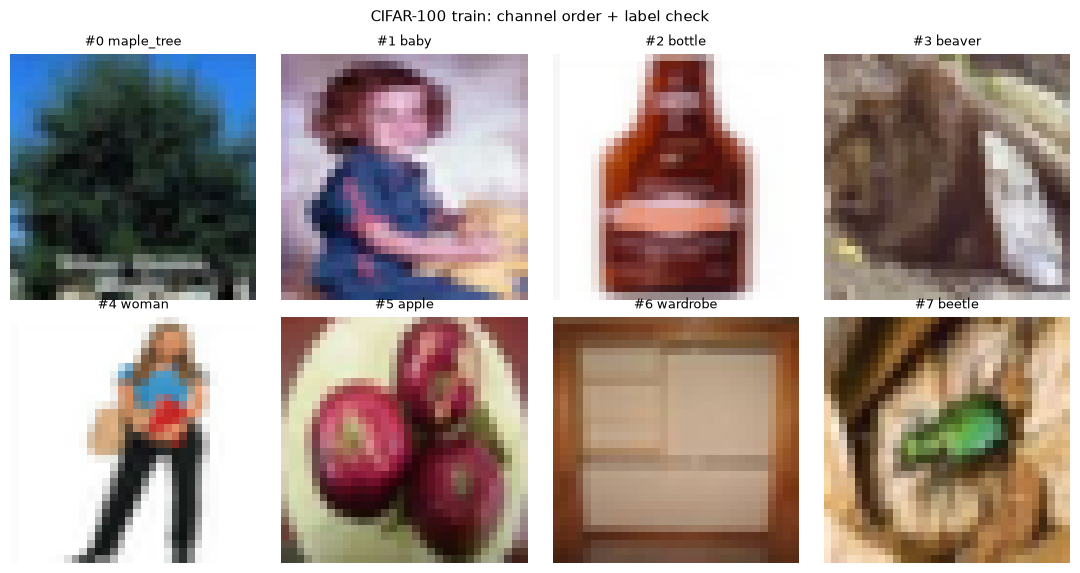

前 2000 张逐通道均值 (R,G,B): [0.51  0.486 0.439]
图已存到: C:\Users\sigridwicks\Desktop\DL HW1\task_b\report\figs\09_data_samples.png


In [5]:
# --- cell 4 · 0.4 自检（二）：画 8 张图，肉眼确认是正常彩色图、标签对得上 ---
# 任务书说这一步能"救命"：C,H,W 与 H,W,C 搞混、通道顺序错、标签错位，
# 都会让模型"照样训练、悄悄变差"。图里的文字用英文（matplotlib 默认字体没有中文，会变豆腐块）
import matplotlib.pyplot as plt
from config import TASKB_ROOT

FIG_DIR = TASKB_ROOT / 'report' / 'figs'          # 图统一落这里，供 report/main.tex 引用
FIG_DIR.mkdir(parents=True, exist_ok=True)

names = cdata.load_label_names()
fig, axes = plt.subplots(2, 4, figsize=(11, 5.8))
for ax, i in zip(axes.ravel(), range(8)):
    img = ds.train.images[i].astype(np.float32) / 255.0      # (3,32,32)，值域 [0,1]
    ax.imshow(img.transpose(1, 2, 0))                        # imshow 要的是 (H,W,C)
    ax.set_title(f'#{i} {names[ds.train.labels[i]]}', fontsize=9)
    ax.axis('off')
fig.suptitle('CIFAR-100 train: channel order + label check', fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_data_samples.png', dpi=150, bbox_inches='tight')
plt.show()

# 自然图像 R > G > B；通道顺序要是搞反了（BGR）这里会反过来
m = ds.train.images[:2000].mean(axis=(0, 2, 3)) / 255.0
print('前 2000 张逐通道均值 (R,G,B):', np.round(m, 3))
print('图已存到:', FIG_DIR / '09_data_samples.png')

In [ ]:
# --- cell 5 · 0.4 补充：batch 级均值"应该"波动多大 ---
# 用**数据集**统计量归一化，所以单个 batch 的均值不该精确为 0。
# 这里量出应有的波动宽度，免得以后看到 -0.1 就以为归一化错了（我第一眼就差点误判）
im_means = ds.train.images[:10000].astype(np.float32).mean(axis=(2, 3)) / 255.0
theory_se = im_means.std(axis=0) / np.asarray(config.CIFAR100_STD) / np.sqrt(128)
print('每张图逐通道均值的 std (raw):', np.round(im_means.std(axis=0), 4), '（CIFAR 图亮度差异很大）')
print('batch=128 的理论标准误      :', np.round(theory_se, 4))

ms = np.array([Xb.mean(axis=(0, 2, 3)) for Xb, _ in cdata.batches(ds.train, 128, rng=np.random.default_rng(1))])
print(f'实测 {len(ms)} 个 batch 的均值分布: mean {np.round(ms.mean(axis=0), 4)}  std {np.round(ms.std(axis=0), 4)}')
print('→ 围绕 0 对称、宽度 ≈ 理论标准误 = 归一化正确，cell 3 里的 -0.107 属正常波动')

In [ ]:
# --- cell 6 · 0.3 纯度守卫（脚本 tests/test_purity.py）—— 报告 B.2 要贴的就是这段输出 ---
# 守卫是独立脚本（终端也能直接 python tests/test_purity.py 跑）；这里把它请进 notebook，
# 让「实现纪律」的证据跟着 Run All 一起留存
import subprocess, sys

r = subprocess.run([sys.executable, str(TASKB_ROOT / 'tests' / 'test_purity.py')],
                   capture_output=True, text=True, encoding='utf-8', errors='replace')
print(r.stdout)
print('exit code:', r.returncode, '（0 = 通过）')

In [ ]:
# --- cell 7 · 0.5 计时基线：读落盘结果（重新测量：python tests/bench_timing.py）---
# 只读 runs/timing/timing.json，不重跑基准 —— 这样 notebook 的 Run All 只要几秒
import json
from config import RUNS_DIR, BLAS_THREADS

tj = json.loads((RUNS_DIR / 'timing' / 'timing.json').read_text(encoding='utf-8'))
tkeys = sorted(tj['threads'], key=int)
batches = tj['assumptions']['batches_per_epoch']

print('=== 1) matmul 吞吐 (GFLOP/s) —— 选线程数用 ===')
print(f'{"layer":20s}' + ''.join(f'{int(t):>8d}T' for t in tkeys))
for i, layer in enumerate(tj['conv_layers']):
    print(f'{layer[0]:20s}' + ''.join(f'{tj["threads"][t]["conv"][i]["gflops"]:>9.2f}' for t in tkeys))

print(f'\n=== 2) 单层 conv 成本 @ {BLAS_THREADS} 线程 (ms/batch) ===')
print(f'{"layer":20s}{"col_MB":>8s}{"copy":>8s}{"gemm":>8s}{"fwd":>8s}{"bwd~2x":>8s}')
for r in tj['threads'][str(BLAS_THREADS)]['conv']:
    fwd = r['copy_ms'] + r['gemm_ms']
    print(f'{r["name"]:20s}{r["col_mb"]:>8.1f}{r["copy_ms"]:>8.1f}{r["gemm_ms"]:>8.1f}{fwd:>8.1f}{fwd * 2:>8.1f}')

print(f'\n=== 3) 内存带宽侧 @ {BLAS_THREADS} 线程：一遍全张量读写 / 一次逐通道归约 (ms) ===')
print(f'{"activation":22s}{"MB/pass":>9s}{"pass":>8s}{"reduce":>8s}')
for a in tj['threads'][str(BLAS_THREADS)]['act']:
    print(f'{str(tuple(a["shape"])):22s}{a["mb_per_pass"]:>9.1f}{a["pass_ms"]:>8.2f}{a["reduce_ms"]:>8.2f}')

print(f'\n=== 4) epoch 外推 (s/epoch, {batches} 个 train batch) ===')
print(f'{"scenario":22s}' + ''.join(f'{int(t):>9d}T' for t in tkeys))
for scenario in ('conv', 'conv+gelu', 'conv+gelu+SN'):
    line = f'{scenario:22s}'
    for t in tkeys:
        line += f'{tj["epoch_seconds"][t][scenario] * batches / 1000:>10.1f}'
    print(line)

print(f'\n结论：线程数定在 {BLAS_THREADS} —— 4T 是吞吐拐点，而带宽受限的部分在 8T/16T 反而变慢；')
print(f'      conv+gelu+SN 全算上 30 个 epoch ≈ '
      f'{tj["epoch_seconds"][str(BLAS_THREADS)]["conv+gelu+SN"] * batches * 30 / 1000 / 60:.0f} 分钟，网络规模不必死抠')